# Linear Regression

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe



Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv")
print(df.shape)

(1314, 8)


Let's see what the first 5 rows of this dataset looks like

In [4]:
print(df.head())


   LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0    11553         1051       1159         336         0            5   
1     8400         1052       1052         288         0            5   
2     8960         1008       1028         360         0            6   
3    11100            0        930         308         0            7   
4    15593         1304       2287         667         0            4   

  Utilities  SalePrice  
0    AllPub     158000  
1    AllPub     138500  
2    AllPub     115000  
3    AllPub      84900  
4    AllPub     225000  


What are all the features present? What is the range for each of the features along with their mean?

In [5]:
print(df.columns)
print(df.describe())

Index(['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea',
       'OverallCond', 'Utilities', 'SalePrice'],
      dtype='str')
             LotArea  TotalBsmtSF    GrLivArea   GarageArea     PoolArea  \
count    1314.000000  1314.000000  1314.000000  1314.000000  1314.000000   
mean    10622.104262  1058.311263  1512.900304   473.480213     2.643075   
std     10430.181058   435.717809   524.854432   213.960987    39.504255   
min      1300.000000     0.000000   334.000000     0.000000     0.000000   
25%      7588.500000   796.000000  1124.250000   336.000000     0.000000   
50%      9501.500000   992.000000  1461.500000   480.000000     0.000000   
75%     11613.500000  1295.250000  1775.750000   576.000000     0.000000   
max    215245.000000  6110.000000  5642.000000  1418.000000   738.000000   

       OverallCond      SalePrice  
count  1314.000000    1314.000000  
mean      5.582192  180795.504566  
std       1.112699   77511.272784  
min       1.000000   34900.0000

### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.
  
These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`
  
These features are called categorical features. We can represent these features as a `One-Hot Representation`
  
  
You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [6]:
df = pd.get_dummies(df, columns=["Utilities"], dtype=float)
print(df.head())

   LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0    11553         1051       1159         336         0            5   
1     8400         1052       1052         288         0            5   
2     8960         1008       1028         360         0            6   
3    11100            0        930         308         0            7   
4    15593         1304       2287         667         0            4   

   SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0     158000               1.0               0.0  
1     138500               1.0               0.0  
2     115000               1.0               0.0  
3      84900               1.0               0.0  
4     225000               1.0               0.0  


In [7]:
data_min = df.min()
data_max = df.max()
data_range = data_max - data_min
data_range = data_range.replace(0, 1)

df_scaled = (df - data_min) / data_range
print(df_scaled.head())

    LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0  0.047924     0.172013   0.155426    0.236953       0.0        0.500   
1  0.033186     0.172177   0.135268    0.203103       0.0        0.500   
2  0.035804     0.164975   0.130746    0.253879       0.0        0.625   
3  0.045806     0.000000   0.112283    0.217207       0.0        0.750   
4  0.066807     0.213421   0.367935    0.470381       0.0        0.375   

   SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0   0.170948               1.0               0.0  
1   0.143869               1.0               0.0  
2   0.111235               1.0               0.0  
3   0.069435               1.0               0.0  
4   0.263991               1.0               0.0  


### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model
  
Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $

*   List item
*   List item

(X, Y)$. These represent the features and targets respectively

In [8]:
x = df_scaled.drop(columns="SalePrice").to_numpy()
y = df_scaled["SalePrice"].to_numpy().reshape(-1, 1)
print(x.shape, y.shape)

(1314, 8) (1314, 1)


## Linear Regression formulation
  
We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction


Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$
  
  
Now how do we extend this to multiple datapoints?  
  
  
Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)


**Answer:** There are 8 features after one-hot encoding, so the model has 8 weights and 1 bias (so 9 parameters).

The equation for all houses is `y_pred = x @ w.T + b`.
Here `x` has shape `(N, 8)`, `w` has shape `(1, 8)`, and predictions have shape `(N, 1)`.

In [9]:
np.random.seed(1)
w = np.random.randn(1, x.shape[1])
b = 0.0

y_pred = x @ w.T + b
print("Number of parameters:", w.size + 1)


Number of parameters: 9


How well does our model perform? Try comparing our predictions with the actual values

**Answer:** Initial predictions are poor because the weights are random and have not learned from the training data. The next cell compares the first five actual and predicted values on the same scaled units.

In [10]:
print("Actual values:")
print(y[:5])
print("Initial predictions:")
print(y_pred[:5])


Actual values:
[[0.17094848]
 [0.14386891]
 [0.11123455]
 [0.0694348 ]
 [0.26399111]]
Initial predictions:
[[ 0.23032154]
 [ 0.25325028]
 [-0.07787756]
 [-0.19929877]
 [ 0.16065395]]


### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

**Answer:** MSE is the average of the squared differences between predicted and actual prices. Squaring makes large errors matter more.

We will assume a linear relationship and independent errors with mean zero and constant variance. Gaussian errors give the usual squared-error likelihood interpretation; calculating MSE itself does not require perfectly Gaussian data.

We will use half-MSE for convenience since the 1/2 cancels the 2 from differentiating the loss fn, so neither gradient below has an extra factor of 2.

In [11]:
def mse_loss_fn(y_true, y_pred):
    return 0.5 * np.mean((y_pred - y_true) ** 2)

print("Initial half-MSE:", mse_loss_fn(y, y_pred))


Initial half-MSE: 0.1255345807455405


Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

In [12]:
def get_gradients(y_true, y_pred, W, b, X):
    m = len(X)
    error = y_pred - y_true
    dW = (1 / m) * (error.T @ X)
    db = np.mean(error)
    return dW, db


Update the weights using the gradients

In [13]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    weights = weights - lr * gradients_weights
    bias = bias - lr * gradients_bias
    return weights, bias


Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs
  
> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code


In [14]:
NUM_EPOCHS = 1000
LEARNING_RATE = 0.05

np.random.seed(1)
w = np.random.randn(1, x.shape[1])
b = 0.0
losses = []

for epoch in range(NUM_EPOCHS):
    y_pred = x @ w.T + b
    loss = mse_loss_fn(y, y_pred)
    losses.append(loss)
    dw, db = get_gradients(y, y_pred, w, b, x)
    w, b = update(w, b, dw, db, LEARNING_RATE)

train_mse = mse_loss_fn(y, x @ w.T + b)
print("Initial half-MSE:", losses[0])
print("Final training half-MSE:", train_mse)


Initial half-MSE:

0.1255345807455405
Final training half-MSE: 0.022972333849576483


Now use matplotlib to plot the loss graph

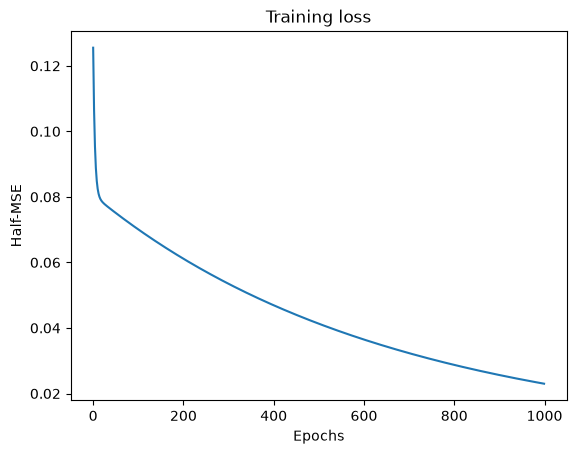

In [15]:
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Half-MSE")
plt.title("Training loss")
plt.show()


### **Testing with test data**

Load and apply all the preprocessing steps used in the training data
for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

To load test data from GitHub, use the code below.

**Answer:** We use the training min/max values so the test data is transformed onto the same scale the model learned from. Recalculating them from the test set would make the same feature value represent a different scaled input.

In [16]:
df_test = pd.read_csv("https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv")
print(df_test.head())
print(df_test.isna().sum())

df_test = pd.get_dummies(df_test, columns=["Utilities"], dtype=float)

# The test set may not contain every Utilities category.
missing_cols = []
for column in df.columns:
    if column not in df_test.columns:
        missing_cols.append(column)
        df_test[column] = 0

# Use the same column order as the training data.
df_test = df_test[df.columns]


   LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0    15623         2396       4476         813       555            5   
1    11952          808       1969         534         0            6   
2     7558          896       1913         342         0            6   
3     6762         1187       1208         632         0            5   
4     8529         1454       1434         527         0            5   

  Utilities  SalePrice  
0    AllPub     745000  
1    AllPub     190000  
2    AllPub     177000  
3    AllPub     206000  
4    AllPub     189000  
LotArea        0
TotalBsmtSF    0
GrLivArea      0
GarageArea     0
PoolArea       0
OverallCond    0
Utilities      0
SalePrice      0
dtype: int64


Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

**Answers:** Some predictions differ substantially from the actual prices, so the model's accuracy is limited.

The test loss is lower than the training loss in this run. The code below prints half-MSE and ordinary MSE.

This can happen because the two sets contain different houses, and the test houses may fit the model better. Training loss is not always lower, especially when training has not fully converged.


In [17]:
df_test_scaled = (df_test - data_min) / data_range

x_test = df_test_scaled.drop(columns="SalePrice").to_numpy()
y_test = df_test_scaled["SalePrice"].to_numpy().reshape(-1, 1)
print(x_test.shape, y_test.shape)


(146, 8) (146, 1)


In [18]:
print("Columns added to the test set:", missing_cols)
print("Training columns:", df.columns)
print("Test columns:", df_test.columns)


Columns added to the test set: ['Utilities_NoSeWa']
Training columns: Index(['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea',
       'OverallCond', 'SalePrice', 'Utilities_AllPub', 'Utilities_NoSeWa'],
      dtype='str')
Test columns: Index(['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea',
       'OverallCond', 'SalePrice', 'Utilities_AllPub', 'Utilities_NoSeWa'],
      dtype='str')


In [19]:
y_pred_test = x_test @ w.T + b
loss_test = mse_loss_fn(y_test, y_pred_test)

# Convert predictions and targets back to original price units.
y_pred_test_scaled = y_pred_test * data_range["SalePrice"] + data_min["SalePrice"]
y_test_scaled = y_test * data_range["SalePrice"] + data_min["SalePrice"]

print("Training half-MSE:", train_mse)
print("Test half-MSE:", loss_test)

print("Test MSE:", 2 * loss_test)


Training half-MSE: 0.022972333849576483
Test half-MSE: 0.018397941400728233
Test MSE: 0.036795882801456466


In [20]:
np.random.seed(1)
idx = np.random.randint(0, x_test.shape[0], 5)
y_pred_test_sample = y_pred_test_scaled[idx].round().astype(int)
y_true_test_sample = y_test_scaled[idx].round().astype(int)

print("Predicted SalePrice:")
print(y_pred_test_sample)
print("Actual SalePrice:")
print(y_true_test_sample)

if loss_test > train_mse:
    print("Test half-MSE is higher than training half-MSE.")
else:
    print("Test half-MSE is lower than or equal to training half-MSE.")


Predicted SalePrice:
[[334830]
 [ 34516]
 [205662]
 [179908]
 [236546]]
Actual SalePrice:
[[100000]
 [150500]
 [135000]
 [250000]
 [124500]]
Test half-MSE is lower than or equal to training half-MSE.
